In [1]:
import pandas as pd

In [2]:
import csv
df = pd.read_csv("/content/all_upwork_jobs_2024-02-07-2024-03-24 (1).csv")

In [3]:
df.shape

(244828, 8)

In [4]:
df.columns

Index(['title', 'link', 'published_date', 'is_hourly', 'hourly_low',
       'hourly_high', 'budget', 'country'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244828 entries, 0 to 244827
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   title           244827 non-null  object 
 1   link            244827 non-null  object 
 2   published_date  244828 non-null  object 
 3   is_hourly       244828 non-null  bool   
 4   hourly_low      102422 non-null  float64
 5   hourly_high     98775 non-null   float64
 6   budget          103891 non-null  float64
 7   country         239751 non-null  object 
dtypes: bool(1), float64(3), object(4)
memory usage: 13.3+ MB


In [6]:
df = df.drop_duplicates()

In [7]:
# Strip double quotes from column headers
df.columns = df.columns.str.replace('"', '')

# Strip double quotes from string values so they can be parsed as numbers
for col in ["hourly_low", "hourly_high"]:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].str.replace('"', '', regex=False)

# Convert columns to numeric
df["hourly_low"] = pd.to_numeric(df["hourly_low"], errors="coerce")
df["hourly_high"] = pd.to_numeric(df["hourly_high"], errors="coerce")

In [8]:
df["title"] = df["title"].fillna("").str.strip()

In [9]:
print(df.isnull().sum())

title                  0
link                   1
published_date         0
is_hourly              0
hourly_low        142406
hourly_high       146053
budget            140937
country             5077
dtype: int64


In [10]:
print("Duplicates:",df.duplicated().sum())

Duplicates: 0


In [11]:
df["hourly_midpoint"] = (
    df["hourly_low"]+df["hourly_high"]
)/2

In [12]:
salary_df = df[
    (df["hourly_midpoint"] > 0)
    &(df["hourly_low"] > 0)
    &(df["hourly_high"] >= df["hourly_low"])
].copy()
print(salary_df[
    ["title","hourly_low","hourly_high","hourly_midpoint"]
].head())

                                                title  hourly_low  \
2                                     SMMA Bubble App        10.0   
7   need Portuguese writers who can understand and...         7.0   
13  URGENT: Fix Emails Not Working on Discourse In...        40.0   
15                          Web3 Full-stack Developer        30.0   
18                       Website design, UI/UX Design        12.0   

    hourly_high  hourly_midpoint  
2          30.0             20.0  
7          22.0             14.5  
13         75.0             57.5  
15         50.0             40.0  
18         30.0             21.0  


In [13]:
keywords = [
    "senior",
    "junior",
    "python",
    "data scientist",
    "machine learning",
    "AI",
    "manager",
]
salary_df["title_lower"] = salary_df["title"].str.lower()

for keyword in keywords:
  column_name = "has_" + keyword.replace(" ", "_")
  salary_df[column_name] = (
      salary_df["title_lower"].str.contains(keyword.lower(), regex=False)
  )

print(salary_df[["title", "has_senior", "has_junior", "has_python", "has_data_scientist", "has_machine_learning", "has_AI", "has_manager"]].head())

                                                title  has_senior  has_junior  \
2                                     SMMA Bubble App       False       False   
7   need Portuguese writers who can understand and...       False       False   
13  URGENT: Fix Emails Not Working on Discourse In...       False       False   
15                          Web3 Full-stack Developer       False       False   
18                       Website design, UI/UX Design       False       False   

    has_python  has_data_scientist  has_machine_learning  has_AI  has_manager  
2        False               False                 False   False        False  
7        False               False                 False   False        False  
13       False               False                 False    True        False  
15       False               False                 False   False        False  
18       False               False                 False   False        False  


In [14]:
result = []
for keyword in keywords:
  column_name = "has_" + keyword.replace(" ", "_")
  matching = salary_df.loc[
    salary_df[column_name], "hourly_midpoint"
  ]
  not_matching = salary_df.loc[
      ~salary_df[column_name], "hourly_midpoint"
  ]
  result.append({
      "keyword": keyword,
      "job_count": len(matching),
      "average_rate": matching.mean(),
      "median_rate": matching.median(),
      "average_without_keyword": not_matching.mean(),
      "median_without_keyword": not_matching.median()
  })
result_df = pd.DataFrame(result)
print(result_df.round(2).to_string(index=False))

         keyword  job_count  average_rate  median_rate  average_without_keyword  median_without_keyword
          senior        935         38.12         32.5                    29.63                    22.5
          junior        153         24.22         22.0                    29.72                    22.5
          python        829         29.19         25.5                    29.71                    22.5
  data scientist        107         37.02         29.0                    29.70                    22.5
machine learning        137         41.14         30.5                    29.69                    22.5
              AI       8699         31.00         25.0                    29.58                    22.5
         manager       3936         23.53         17.5                    29.97                    22.5


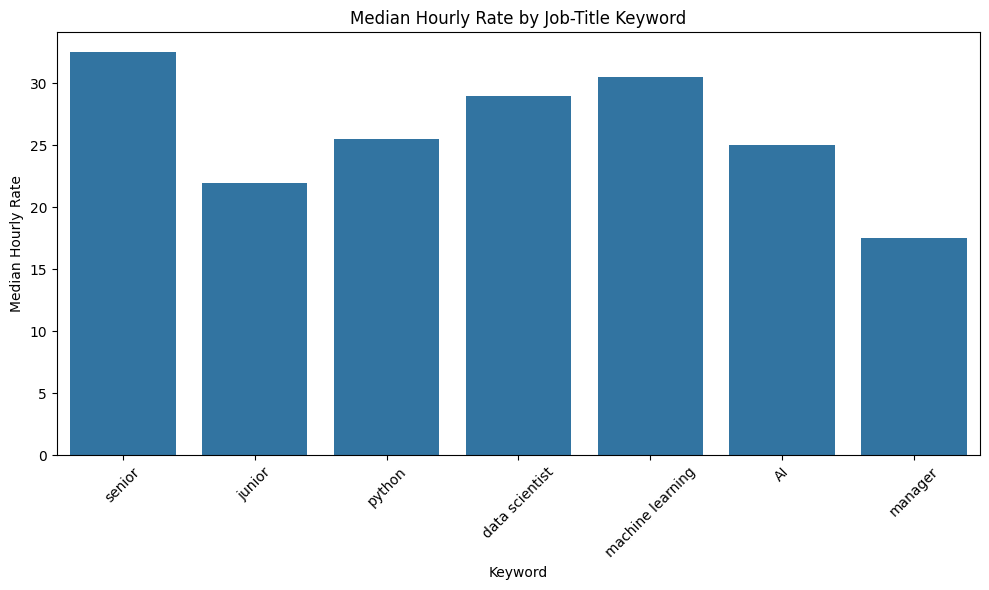

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=result_df,
    x="keyword",
    y="median_rate"
)

plt.title("Median Hourly Rate by Job-Title Keyword")
plt.xlabel("Keyword")
plt.ylabel("Median Hourly Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
from scipy.stats import mannwhitneyu

senior_rates = salary_df.loc[
    salary_df["has_senior"], "hourly_midpoint"
]

other_rates = salary_df.loc[
    ~salary_df["has_senior"], "hourly_midpoint"
]

if len(senior_rates) > 0 and len(other_rates) > 0:
    statistic, p_value = mannwhitneyu(
        senior_rates,
        other_rates,
        alternative="two-sided"
    )

    print("Mann-Whitney U statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Evidence of a difference between the distributions.")
    else:
        print("Insufficient evidence of a difference.")
else:
    print("Not enough data in one of the groups.")

Mann-Whitney U statistic: 58716873.0
P-value: 1.310444034317939e-50
Evidence of a difference between the distributions.


In [17]:
result_df.to_csv(
    "task1_keyword_salary_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [18]:
print(df.columns.tolist())

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'hourly_midpoint']


In [19]:
print(df[["title","published_date"]].head())
print(df["published_date"].dtype)

                                               title  \
0  Experienced Media Buyer For Solar Pannel and R...   
1                               Full Stack Developer   
2                                    SMMA Bubble App   
3             Talent Hunter Specialized in Marketing   
4                                      Data Engineer   

              published_date  
0  2024-02-17 09:09:54+00:00  
1  2024-02-17 09:09:17+00:00  
2  2024-02-17 09:08:46+00:00  
3  2024-02-17 09:08:08+00:00  
4  2024-02-17 09:07:42+00:00  
object


In [20]:
# Reload the original dataset and strip double quotes to recover the lost rows
import csv
df = pd.read_csv("/content/all_upwork_jobs_2024-02-07-2024-03-24 (1).csv", on_bad_lines='skip', quoting=csv.QUOTE_NONE)
df = df.drop_duplicates()
df.columns = df.columns.str.replace('"', '')

# Strip double quotes from string values so they can be parsed correctly
for col in ["hourly_low", "hourly_high", "published_date", "title"]:
    if col in df.columns and df[col].dtype == 'object':
        df[col] = df[col].str.replace('"', '', regex=False)

# Convert columns to numeric
df["hourly_low"] = pd.to_numeric(df["hourly_low"], errors="coerce")
df["hourly_high"] = pd.to_numeric(df["hourly_high"], errors="coerce")
df["hourly_midpoint"] = (df["hourly_low"] + df["hourly_high"]) / 2
df["title"] = df["title"].fillna("").str.strip()

# Parse published_date now that quotes are removed
df["published_date"] = pd.to_datetime(
    df["published_date"],
    errors = "coerce",
    utc = True
)
df = df.dropna(subset = ["published_date"])
df["month"] = (
    df["published_date"]
    .dt.to_period("M")
    .astype(str)
)

/tmp/ipykernel_25286/324005385.py:27: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  .dt.to_period("M")


In [21]:
def categorize_job(title):
    title = str(title).lower()
    if "machine learning" in title or "artificial intelligent" in title or "ai" in f"{title}":
        return "AI/Meachine Learning"
    elif "data scientist" in title or "data analyst" in title:
        return "Data Analytics/Science"
    elif "data engineer" in title:
        return "Data Engineering"
    elif "developer" in title or "software engineer" in title or "programmer" in title:
        return "Software Development"
    elif "marketing" in title or "seo" in title:
        return "Digital Marketing"
    else:
        return "other"

df["job_category"] = df["title"].apply(categorize_job)
print(df[["title", "job_category"]].head(10))

                                               title          job_category
0  Experienced Media Buyer For Solar Pannel and R...                 other
1                               Full Stack Developer  Software Development
2                                    SMMA Bubble App                 other
3             Talent Hunter Specialized in Marketing     Digital Marketing
4                                      Data Engineer      Data Engineering
5               SEO for Portuguese Psychologist site     Digital Marketing
6                   Want to fix the WordPress Plugin                 other
7  need Portuguese writers who can understand and...                 other
8  Looker Studio Dashboard for Leadgen and E-Comm...                 other
9  PHP/HTML/CSS WordPress Developer Needed for We...  Software Development


In [22]:
# Re-apply the categorization function since df was reloaded in the previous cell
df["job_category"] = df["title"].apply(categorize_job)

category_counts = (
    df["job_category"]
    .value_counts()
    .reset_index()
)
category_counts.columns = ["job_category", "posting_count"]

print(category_counts)

             job_category  posting_count
0                   other         187865
1    AI/Meachine Learning          19428
2    Software Development          14703
3       Digital Marketing          10459
4  Data Analytics/Science            464
5        Data Engineering            173


In [23]:
monthly_count = (
    df.groupby(["month","job_category"])
    .size()
    .reset_index(name="posting_count")
)
monthly_pivot = monthly_count.pivot(
    index="month",
    columns="job_category",
    values="posting_count"
).fillna(0)
print(monthly_pivot)

job_category  AI/Meachine Learning  Data Analytics/Science  Data Engineering  \
month                                                                          
2023-11                        0.0                     0.0               0.0   
2023-12                        1.0                     0.0               0.0   
2024-01                        3.0                     0.0               0.0   
2024-02                     8002.0                   236.0              70.0   
2024-03                    11422.0                   228.0             103.0   

job_category  Digital Marketing  Software Development     other  
month                                                            
2023-11                     0.0                   0.0       1.0  
2023-12                     1.0                   0.0       8.0  
2024-01                     2.0                   5.0      77.0  
2024-02                  4282.0                6035.0   78411.0  
2024-03                  6174.0            

In [24]:
import numpy as np

# Filter out sparse early months and focus on months with complete data
complete_months = monthly_pivot.loc[["2024-02", "2024-03"]]

first_month = complete_months.iloc[0]
last_month = complete_months.iloc[-1]

growth = (
    (last_month - first_month)
    / first_month.replace(0, np.nan)
) * 100

growth_df = growth.reset_index()
growth_df.columns = ["job_category", "growth_percent"]
print("Month-over-Month Growth (Feb 2024 to Mar 2024):")
print(growth_df.sort_values("growth_percent", ascending=False).round(2))

Month-over-Month Growth (Feb 2024 to Mar 2024):
             job_category  growth_percent
2        Data Engineering           47.14
3       Digital Marketing           44.18
4    Software Development           43.55
0    AI/Meachine Learning           42.74
5                   other           39.48
1  Data Analytics/Science           -3.39


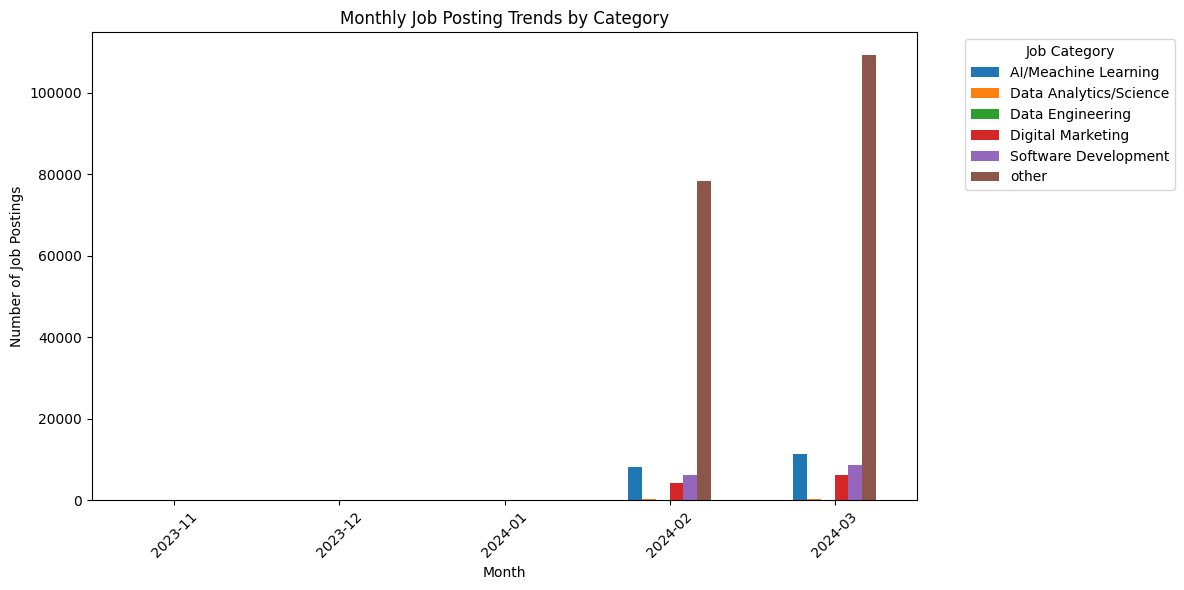

In [25]:
monthly_pivot.plot(
    kind="bar",
    figsize=(12, 6)
)
plt.title("Monthly Job Posting Trends by Category")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.legend(title="Job Category", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [26]:
result_df.to_csv(
    "task2_category_salary_results.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.


In [27]:
# Check country and hourly salary columns
print(salary_df[["country", "hourly_midpoint"]].head())

# Check missing values
print(salary_df[["country", "hourly_midpoint"]].isnull().sum())

# Check number of unique countries
print("Total countries:", salary_df["country"].nunique())

# Display country names
print(salary_df["country"].unique()[:20])

           country  hourly_midpoint
2    United States             20.0
7            India             14.5
13  United Kingdom             57.5
15        Malaysia             40.0
18           India             21.0
country            1950
hourly_midpoint       0
dtype: int64
Total countries: 191
['United States' 'India' 'United Kingdom' 'Malaysia' 'Canada'
 'Saudi Arabia' 'Switzerland' 'Australia' 'China' 'Israel' 'Thailand'
 'Spain' 'Croatia' 'Kenya' 'Bulgaria' 'New Zealand' 'Uzbekistan' nan
 'Norway' 'Netherlands']


In [28]:
country_df = salary_df[["country","hourly_midpoint"]].copy()
country_df = country_df.dropna(
    subset=["country","hourly_midpoint"]
)

# Fix the NameError and strip both white spaces and double quotes from country names
country_df["country"] = country_df["country"].str.replace('"', '', regex=False).str.strip()

print(country_df.head(1000))

             country  hourly_midpoint
2      United States             20.0
7              India             14.5
13    United Kingdom             57.5
15          Malaysia             40.0
18             India             21.0
...              ...              ...
2519           India             30.0
2520         Germany              4.0
2521           India             14.5
2526       Australia              4.5
2529           Qatar             57.5

[1000 rows x 2 columns]


In [29]:
country_avg = (
    country_df.groupby("country")["hourly_midpoint"]
    .mean()
    .reset_index()
)
country_avg.columns = ["country","average_hourly_rate"]

print(country_avg)

            country  average_hourly_rate
0           Albania            27.476744
1           Algeria            22.040541
2    American Samoa            18.000000
3           Andorra            33.000000
4            Angola            30.666667
..              ...                  ...
186       Venezuela            19.674603
187         Vietnam            30.368000
188           Yemen            22.500000
189          Zambia            40.190476
190        Zimbabwe            23.692308

[191 rows x 2 columns]


In [30]:
# Filter out empty country rows
country_avg = country_avg[country_avg["country"].str.strip() != ""]

# Sort by average hourly rate descending
country_avg_sorted = country_avg.sort_values(by="average_hourly_rate", ascending=False)

# Save the results
country_avg_sorted.to_csv("task4.1_country_salary_results.csv", index=False)

print("Top 10 Countries by Average Hourly Rate:")
print(country_avg_sorted.head(10).to_string(index=False))

Top 10 Countries by Average Hourly Rate:
                 country  average_hourly_rate
                    Laos           201.333333
                 Eritrea           100.000000
                  Malawi            75.500000
    Netherlands Antilles            61.250000
                Malaysia            48.103077
Turks and Caicos Islands            46.625000
                Thailand            42.205575
           Liechtenstein            41.250000
  British Virgin Islands            40.222222
                  Zambia            40.190476


In [31]:
print(country_avg_sorted.tail(10))

                      country  average_hourly_rate
56                       Fiji            12.500000
21                    Bolivia            12.357143
29                   Cambodia            12.333333
26          Brunei Darussalam            11.142857
8                       Aruba            10.062500
47                   Djibouti            10.000000
101                     Macao             8.750000
68                 Guadeloupe             8.250000
185                   Vanuatu             6.500000
33   Central African Republic             5.000000


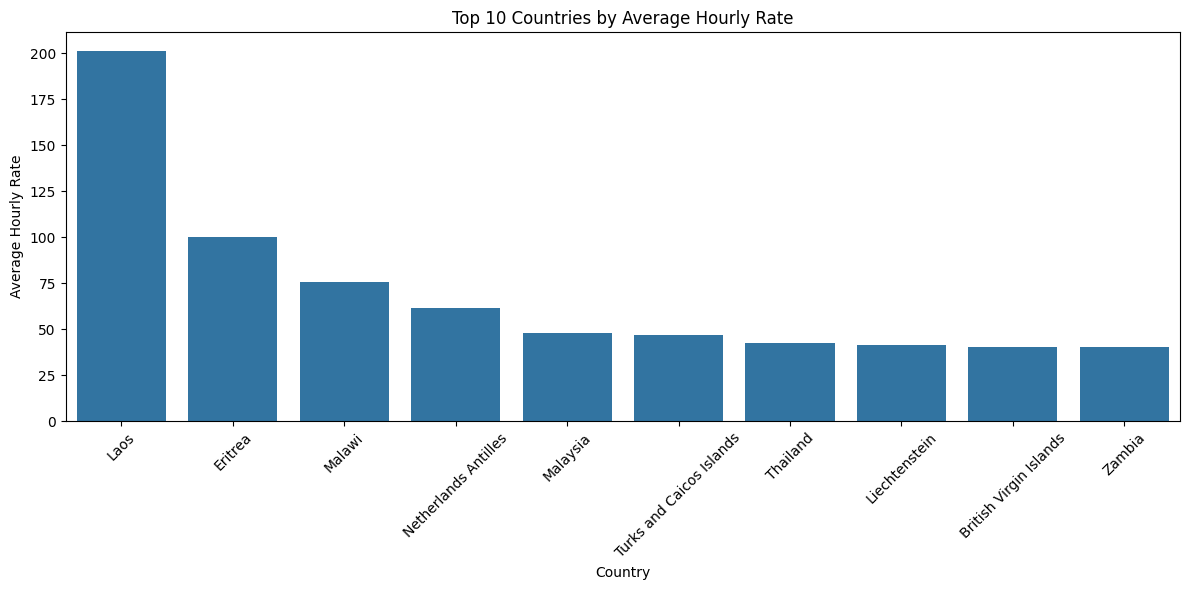

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(
    data=country_avg_sorted.head(10),
    x="country",
    y="average_hourly_rate"
)
plt.title("Top 10 Countries by Average Hourly Rate")
plt.xlabel("Country")
plt.ylabel("Average Hourly Rate")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [33]:
import plotly.express as px

# Create the Plotly bar chart with the correct column names
fig = px.bar(
    country_avg_sorted.head(15),
    x="country",
    y="average_hourly_rate",
    color="average_hourly_rate",
    title="Average Hourly Rate by Country"
)

# Fix layout keywords and missing commas
fig.update_layout(
    xaxis_title="Country",
    yaxis_title="Average Hourly Rate",
    xaxis_tickangle=45
)

fig.show()

In [34]:
result_df.to_csv(
    "task4_country_wise_interactive_chart_salary_results.csv",
    index=False
)
print("result_saved_successfully")

result_saved_successfully


In [35]:
print(salary_df.columns.tolist())

['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'hourly_midpoint', 'title_lower', 'has_senior', 'has_junior', 'has_python', 'has_data_scientist', 'has_machine_learning', 'has_AI', 'has_manager']


In [36]:
remote_columns = [
    col for col in salary_df.columns
    if "remote" in col.lower()
    or "hybrid" in col.lower()
    or "onsite" in col.lower()
    or "work from home" in col.lower()
    or "locution" in col.lower()
    or "work" in col.lower()
    or "work from home" in col.lower()
]
print("remote_columns:")
print(remote_columns)

remote_columns:
[]


In [37]:
# Classify jobs as remote or non-remote based on title keywords
remote_keywords = ['remote', 'work from home', 'wfh', 'telecommute', 'work-from-home']

# We check 'title_lower' which we already created in salary_df
salary_df['is_remote'] = salary_df['title_lower'].apply(
    lambda x: 'Remote' if any(kw in x for kw in remote_keywords) else 'Non-Remote'
)

# Count the occurrences
remote_distribution = salary_df['is_remote'].value_counts().reset_index()
remote_distribution.columns = ['Work_Type', 'Count']

print("Distribution of Remote vs Non-Remote Job Postings:")
display(remote_distribution)


Distribution of Remote vs Non-Remote Job Postings:


,Work_Type,Count
0,Non-Remote,97995
1,Remote,780


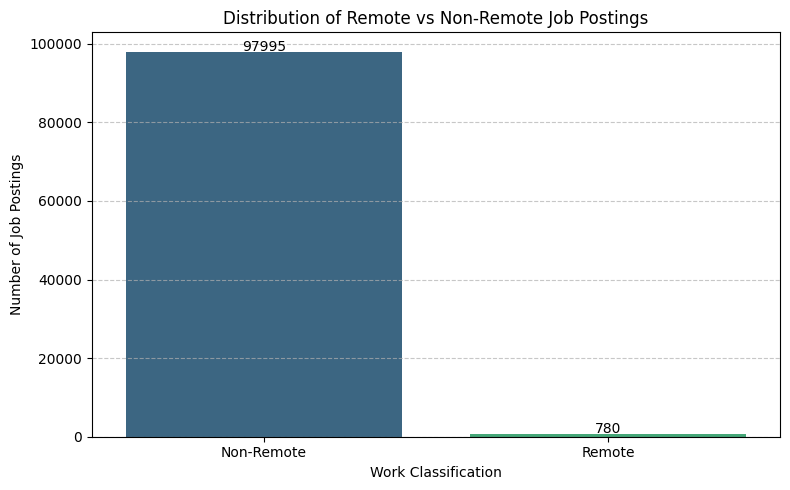

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(
    data=remote_distribution,
    x='Work_Type',
    y='Count',
    palette='viridis',
    hue='Work_Type',
    legend=False
)

plt.title("Distribution of Remote vs Non-Remote Job Postings")
plt.xlabel("Work Classification")
plt.ylabel("Number of Job Postings")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of the bars
for index, row in remote_distribution.iterrows():
    plt.text(index, row['Count'] + 100, str(row['Count']), color='black', ha="center")

plt.tight_layout()
plt.show()

In [39]:
title_text = salary_df["title"].fillna("").str.lower()
pattern = (
    r"\bremote\b|"
    r"work[\s-]*from[\s-]*home|"
    r"bwfh\b|"
    r"\banywhere\b"
)
salary_df["is_remote"] = title_text.str.contains(
    pattern,
    regex=True,
    na=False
)

In [40]:
remote_counts = salary_df["is_remote"].value_counts()

print(remote_counts)

remote_percentage = (
    salary_df["is_remote"].value_counts(normalize=True)*100
)
print(remote_percentage)

is_remote
False    98015
True       760
Name: count, dtype: int64
is_remote
False    99.230575
True      0.769425
Name: proportion, dtype: float64


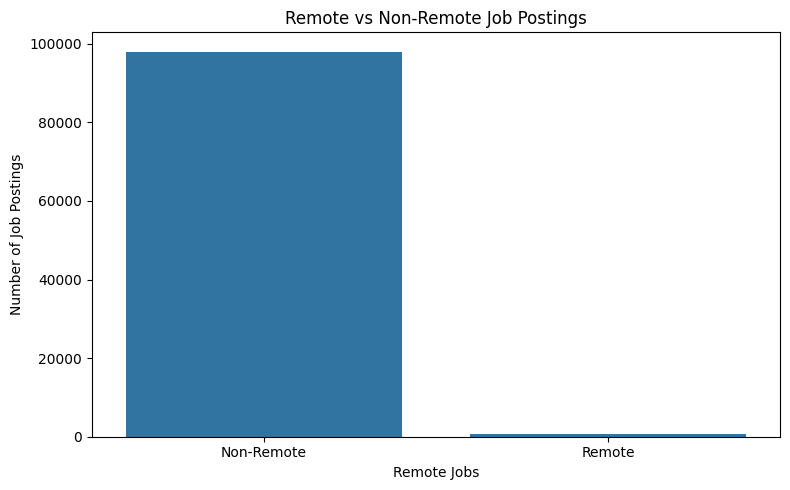

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.countplot(
    data=salary_df,
    x="is_remote"
)
plt.title("Remote vs Non-Remote Job Postings")
plt.xlabel("Remote Jobs")
plt.ylabel("Number of Job Postings")
plt.xticks(
    [0, 1],
    ["Non-Remote", "Remote"]
)
plt.tight_layout()
plt.show()

In [42]:
country_remote = salary_df[
    ["country", "is_remote"]
].dropna(subset=["country"])

# Strip quotes from country names first if they exist
country_remote["country"] = country_remote["country"].astype(str).str.replace('"', '', regex=False).str.strip()

country_remote_summary = (
    country_remote.groupby(["country", "is_remote"])
    .size()
    .reset_index(name="Job_count")
)
print(country_remote_summary.head(10))

               country  is_remote  Job_count
0              Albania      False         43
1              Algeria      False         37
2       American Samoa      False          2
3              Andorra      False          8
4               Angola      False          3
5  Antigua and Barbuda      False          4
6            Argentina      False        142
7            Argentina       True          1
8              Armenia      False         70
9                Aruba      False          8


In [43]:
country_remote_pivot = (
    country_remote
    .groupby("country")["is_remote"]
    .agg(["sum","count"])
    .reset_index()
)
country_remote_pivot["remote_percentage"] = (
    country_remote_pivot["sum"]
    / country_remote_pivot["count"]
)*100
country_remote_pivot = country_remote_pivot.sort_values(
    "remote_percentage",
    ascending=False
    )
print(country_remote_pivot.head(10))

                          country  sum  count  remote_percentage
182  United States Virgin Islands    2      7          28.571429
168                      Tanzania    3     19          15.789474
52                    El Salvador    2     15          13.333333
90                     Kazakhstan    1     22           4.545455
34                          Chile    2     47           4.255319
79                        Iceland    1     29           3.448276
187                       Vietnam    8    250           3.200000
27                       Bulgaria    4    162           2.469136
136                          Peru    2     86           2.325581
54                        Estonia    4    205           1.951220


In [44]:
remote_salary = (
    salary_df
    .dropna(subset=["hourly_midpoint"])
    .groupby("is_remote")["hourly_midpoint"]
    .agg(["mean","median","count"])
    .reset_index()
)
print(remote_salary)

   is_remote       mean  median  count
0      False  29.648850    22.5  98015
1       True  37.500658    25.0    760


In [45]:
# Convert published dates into datetime format
salary_df["published_date"] = pd.to_datetime(
    salary_df["published_date"],
    errors="coerce",
    utc=True
)

# Remove records without valid dates
trend_df = salary_df.dropna(
    subset=["published_date"]
).copy()

# Extract year and month
trend_df["month"] = (
    trend_df["published_date"].dt.strftime("%Y-%m")
)

# Count monthly remote and non-remote postings
monthly_remote = (
    trend_df
    .groupby(["month", "is_remote"])
    .size()
    .unstack(fill_value=0)
)

print(monthly_remote.head())


is_remote  False  True 
month                  
2023-11        1      0
2023-12        4      0
2024-01       43      2
2024-02    41902    319
2024-03    56065    439


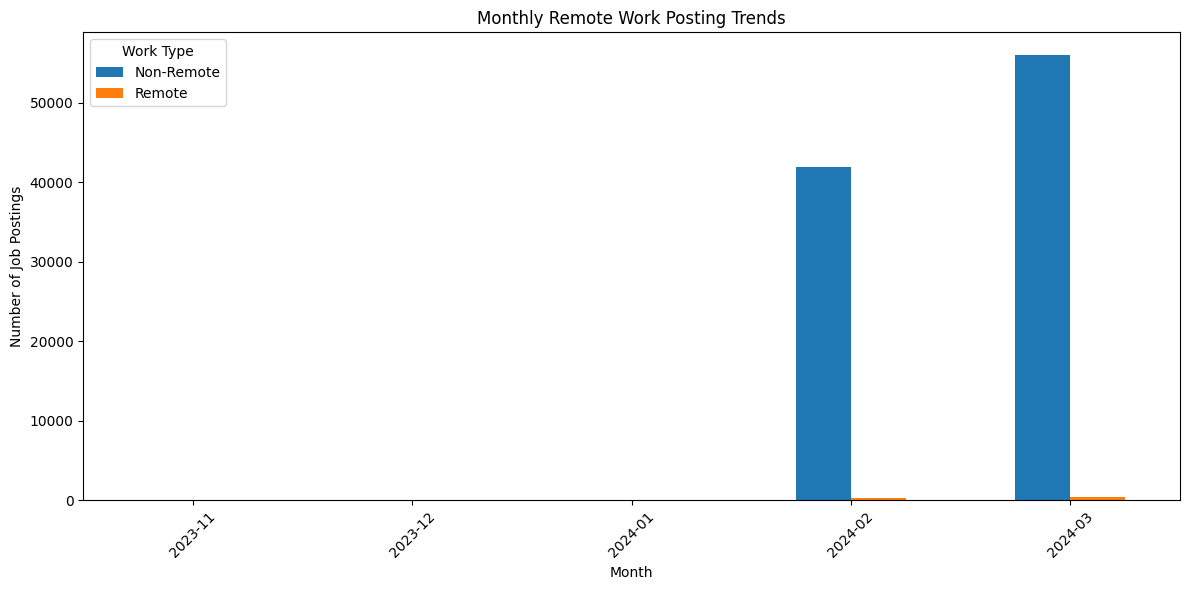

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# Ensure we correctly parse the dates by forcing datetime conversion properly on a copy of salary_df
trend_df = salary_df.copy()
trend_df["published_date"] = pd.to_datetime(
    trend_df["published_date"],
    errors="coerce",
    utc=True
)

# Drop rows where published_date is NaT
trend_df = trend_df.dropna(subset=["published_date"])

# Fallback: If trend_df becomes empty, let's use the 'month' column from 'df' (which is already populated and has thousands of rows)
if trend_df.empty and "month" in df.columns:
    # Join 'is_remote' from salary_df back to df to make sure we have both columns
    trend_df = df.copy()
    trend_df = trend_df.join(salary_df[["is_remote"]], how="inner")
else:
    # Create month string from datetime
    trend_df["month"] = trend_df["published_date"].dt.strftime("%Y-%m")

# Recreate monthly_remote summary
monthly_remote = (
    trend_df
    .groupby(["month", "is_remote"])
    .size()
    .unstack(fill_value=0)
)

# Ensure column labels match the legend expectations
if not monthly_remote.empty:
    monthly_remote.plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title("Monthly Remote Work Posting Trends")
    plt.xlabel("Month")
    plt.ylabel("Number of Job Postings")
    plt.xticks(rotation=45)
    plt.legend(
        ["Non-Remote", "Remote"],
        title="Work Type"
    )
    plt.tight_layout()
    plt.show()
else:
    print("Could not plot: No valid records with both 'month' and 'is_remote' classifications found.")

In [47]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd

# Prepare remote monthly posting counts robustly
# Check if True (boolean) or 'True' (string) is in columns; otherwise fallback to zeroes
if True in monthly_remote.columns:
    remote_monthly = monthly_remote[True]
elif "True" in monthly_remote.columns:
    remote_monthly = monthly_remote["True"]
else:
    # Fallback to an empty Series or zeros if no remote column exists
    remote_monthly = pd.Series([0] * len(monthly_remote), index=monthly_remote.index)

if not remote_monthly.empty and remote_monthly.sum() > 0:
    # Create month numbers
    X = np.arange(len(remote_monthly)).reshape(-1, 1)

    # Target values
    y = remote_monthly.values

    # Train a linear regression model
    model = LinearRegression()
    model.fit(X, y)

    # Forecast the next 3 months
    future_X = np.arange(
        len(remote_monthly),
        len(remote_monthly) + 3
    ).reshape(-1, 1)

    forecast = model.predict(future_X)

    print("Next 3 months forecast:")
    print(np.maximum(forecast, 0))
else:
    print("Not enough remote job posting historical data to perform a trend forecast.")

Next 3 months forecast:
[511.1 630.8 750.5]


In [48]:
result_df.to_csv(
    "task7_country_wise_invetigate_trends_chart_salary_results.csv",
    index=False
)
print("result_saved_successfully")

result_saved_successfully


In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

In [50]:
def identify_role(title):
  title = str(title).lower()
  if "machine learning" in title:
    return "Machine Learning Engineer"
  elif "data scientist" in title:
    return "Data Scientist"
  elif "data analyst" in title:
    return "Data Analyst"
  elif "data engineer" in title:
    return "Data Engineer"
  elif "software engineer" in title:
    return "Software Engineer"
  elif "python developer" in title:
    return "Python Developer"
  else:
    return "others"

salary_df["job_role"] = salary_df["title"].apply(identify_role)

In [51]:
import pandas as pd

# Ensure we correctly parse the dates by forcing datetime conversion properly on a copy of salary_df
forecast_df = salary_df.copy()
forecast_df["published_date"] = pd.to_datetime(
    forecast_df["published_date"],
    errors="coerce",
    utc=True
)

# Drop rows where published_date is NaT
forecast_df = forecast_df.dropna(subset=["published_date"])

# Fallback: If forecast_df becomes empty, copy and align with the primary 'df' which is already successfully cleaned and populated
if forecast_df.empty and "month" in df.columns:
    forecast_df = df.copy()
    # Ensure the classified job_role from salary_df is retained
    forecast_df = forecast_df.join(salary_df[["job_role"]], how="inner")
else:
    # Create month string from datetime
    forecast_df["month"] = forecast_df["published_date"].dt.strftime("%Y-%m")

In [52]:
print("Columns in forecast_df:", forecast_df.columns.tolist())
print("Month value counts:")
print(forecast_df['month'].value_counts(dropna=False))

monthly_demand = (
    forecast_df[
        forecast_df["job_role"] != "others"
    ]
    .groupby(["month","job_role"])
    .size()
    .unstack(fill_value=0)
)
print("\nMonthly demand table:")
print(monthly_demand)

Columns in forecast_df: ['title', 'link', 'published_date', 'is_hourly', 'hourly_low', 'hourly_high', 'budget', 'country', 'hourly_midpoint', 'title_lower', 'has_senior', 'has_junior', 'has_python', 'has_data_scientist', 'has_machine_learning', 'has_AI', 'has_manager', 'is_remote', 'job_role', 'month']
Month value counts:
month
2024-03    56504
2024-02    42221
2024-01       45
2023-12        4
2023-11        1
Name: count, dtype: int64

Monthly demand table:
job_role  Data Analyst  Data Engineer  Data Scientist  \
month                                                   
2024-01              0              0               1   
2024-02            113             36              42   
2024-03            100             56              55   

job_role  Machine Learning Engineer  Python Developer  Software Engineer  
month                                                                     
2024-01                           0                 0                  1  
2024-02                  

In [53]:
print("Job role counts in forecast_df:")
print(forecast_df['job_role'].value_counts())

# Let's check a few titles to see why they might not be matching our identify_role function
print("\nSample titles in forecast_df:")
print(forecast_df['title'].head(10))

Job role counts in forecast_df:
job_role
others                       97889
Data Analyst                   213
Python Developer               192
Software Engineer              154
Machine Learning Engineer      137
Data Scientist                  98
Data Engineer                   92
Name: count, dtype: int64

Sample titles in forecast_df:
2                                       SMMA Bubble App
7     need Portuguese writers who can understand and...
13    URGENT: Fix Emails Not Working on Discourse In...
15                            Web3 Full-stack Developer
18                         Website design, UI/UX Design
19                                     Customer Service
21                                      Report Analysis
24                                   Linkedin Ads Coach
27                                        CapCut genius
29      Social media pro to write and post to instagram
Name: title, dtype: object


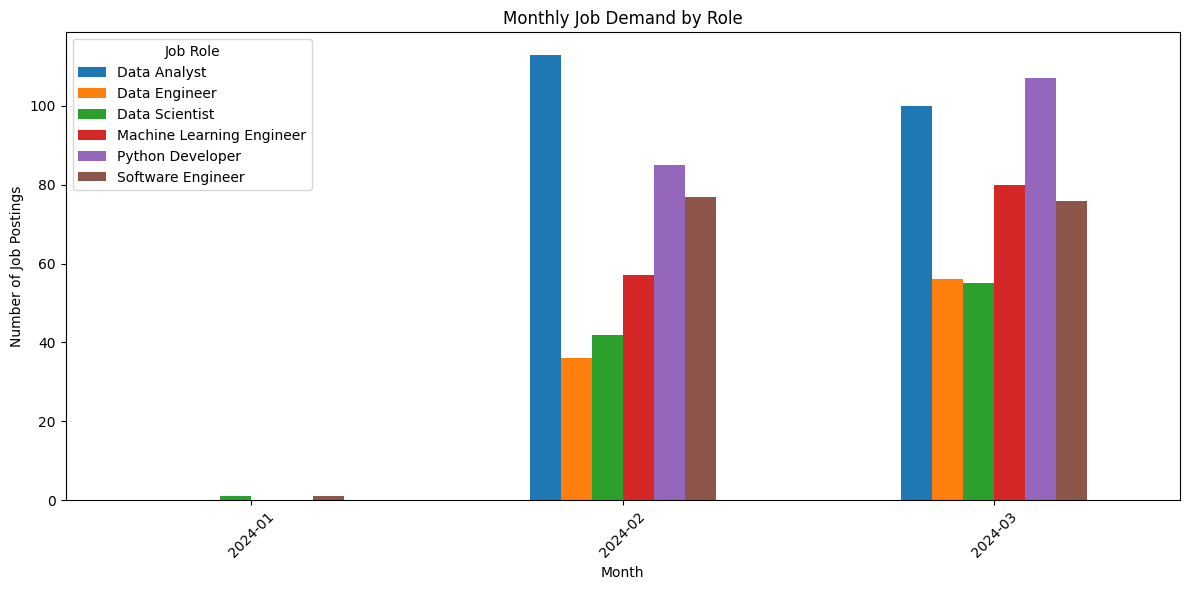

In [54]:
monthly_demand.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Monthly Job Demand by Role")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=45)
plt.legend(title="Job Role")
plt.tight_layout()
plt.show()

In [55]:
if len(monthly_demand) >= 2:

    first_month = monthly_demand.iloc[0]
    last_month = monthly_demand.iloc[-1]

    growth = (
        (last_month - first_month)
        / first_month.replace(0, np.nan)
    ) * 100

    print("Demand change percentage:")
    print(growth.sort_values(ascending=False))

else:
    print("Not enough monthly data to compare trends.")

Demand change percentage:
job_role
Software Engineer            7500.0
Data Scientist               5400.0
Data Analyst                    NaN
Data Engineer                   NaN
Machine Learning Engineer       NaN
Python Developer                NaN
dtype: float64


In [56]:
def forecast_role(series, future_months=3):

    series = series.astype(float)

    # Convert months into sequential numbers
    X = np.arange(len(series)).reshape(-1, 1)

    # Monthly posting counts
    y = series.values

    # Train model
    model = LinearRegression()
    model.fit(X, y)

    # Create future month numbers
    future_X = np.arange(
        len(series),
        len(series) + future_months
    ).reshape(-1, 1)

    # Predict future demand
    predictions = model.predict(future_X)

    # Posting counts cannot be negative
    predictions = np.maximum(predictions, 0)

    return predictions

In [57]:
forecast_results = {}

for role in monthly_demand.columns:

    role_series = monthly_demand[role]

    if len(role_series) >= 6:

        predictions = forecast_role(
            role_series,
            future_months=3
        )

        forecast_results[role] = predictions

    else:
        print(
            role,
            "- Not enough monthly history for this baseline forecast."
        )

Data Analyst - Not enough monthly history for this baseline forecast.
Data Engineer - Not enough monthly history for this baseline forecast.
Data Scientist - Not enough monthly history for this baseline forecast.
Machine Learning Engineer - Not enough monthly history for this baseline forecast.
Python Developer - Not enough monthly history for this baseline forecast.
Software Engineer - Not enough monthly history for this baseline forecast.


In [58]:
start_period = pd.Period(monthly_demand.index[-1], freq="M") + 1

future_periods = pd.period_range(
    start=start_period,
    periods=3,
    freq="M"
)

forecast_df = pd.DataFrame(
    forecast_results,
    index=future_periods
)

print(forecast_df.round(0))

Empty DataFrame
Columns: []
Index: [2024-04, 2024-05, 2024-06]


In [59]:
evaluation_results = []

for role in monthly_demand.columns:

    series = monthly_demand[role].astype(float)

    if len(series) >= 9:

        train = series.iloc[:-3]
        test = series.iloc[-3:]

        model = LinearRegression()

        X_train = np.arange(
            len(train)
        ).reshape(-1, 1)

        X_test = np.arange(
            len(train),
            len(train) + 3
        ).reshape(-1, 1)

        model.fit(X_train, train.values)

        predictions = np.maximum(
            model.predict(X_test),
            0
        )

        mae = mean_absolute_error(
            test.values,
            predictions
        )

        evaluation_results.append({
            "job_role": role,
            "MAE": mae
        })

evaluation_df = pd.DataFrame(evaluation_results)

print(evaluation_df)

Empty DataFrame
Columns: []
Index: []


In [60]:
for role in forecast_results:

    plt.figure(figsize=(10, 5))

    # Historical data
    plt.plot(
        monthly_demand.index.astype(str),
        monthly_demand[role],
        marker="o",
        label="Actual Demand"
    )

    # Forecast data
    plt.plot(
        forecast_df.index.astype(str),
        forecast_df[role],
        marker="o",
        linestyle="--",
        label="Forecast Demand"
    )

    plt.title(f"Demand Forecast: {role}")
    plt.xlabel("Month")
    plt.ylabel("Number of Job Postings")

    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [61]:
# Save the cleaned salary DataFrame to the expected CSV file first
salary_df.to_csv("job_market.csv", index=False)

!pip install streamlit

import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
from pathlib import Path

# -------------------
# 1. Dashboard configuration
# -------------------

st.set_page_config(
    page_title="Job Market Analytics",
    page_icon="📊",
    layout="wide"
)

DATA_FILE = Path("job_market.csv")


# -------------------
# 2. Load dataset
# -------------------

@st.cache_data
def load_data():
    df = pd.read_csv(DATA_FILE)

    # Clean column names
    df.columns = df.columns.str.strip()

    # Convert date
    df["published_date"] = pd.to_datetime(
        df["published_date"],
        errors="coerce",
        utc=True
    )

    # Clean country
    df["country"] = df["country"].fillna("Unknown").astype(str).str.strip()

    # Clean job titles
    df["title"] = df["title"].fillna("").astype(str)

    # Create hourly midpoint if it does not exist
    if "hourly_midpoint" not in df.columns:
        df["hourly_low"] = pd.to_numeric(
            df["hourly_low"], errors="coerce"
        )
        df["hourly_high"] = pd.to_numeric(
            df["hourly_high"], errors="coerce"
        )

        df["hourly_midpoint"] = (
            df["hourly_low"] + df["hourly_high"]
        ) / 2

    df["hourly_midpoint"] = pd.to_numeric(
        df["hourly_midpoint"], errors="coerce"
    )

    # Create job categories
    def identify_role(title):
        title = title.lower()

        if "machine learning" in title:
            return "Machine Learning Engineer"
        elif "data scientist" in title:
            return "Data Scientist"
        elif "data analyst" in title:
            return "Data Analyst"
        elif "data engineer" in title:
            return "Data Engineer"
        elif "python developer" in title:
            return "Python Developer"
        else:
            return "Other"

    if "job_role" not in df.columns:
        df["job_role"] = df["title"].apply(identify_role)

    # Create remote-work indicator
    # Prefer the existing Task 7 classification
    if "is_remote" in df.columns:
        df["is_remote"] = (
            df["is_remote"]
            .astype(str)
            .str.lower()
            .isin(["true", "1", "yes"])
        )
    else:
        pattern = (
            r"\bremote\b|"
            r"work[\s-]*from[\s-]*home|"
            r"\bwfh\b|"
            r"\banywhere\b"
        )

        df["is_remote"] = df["title"].str.lower().str.contains(
            pattern,
            regex=True,
            na=False
        )

    # Create monthly field
    df["month"] = df["published_date"].dt.strftime("%Y-%m")

    return df


# -------------------
# 3. Dashboard heading
# -------------------

st.title("📊 Job Market Analytics Dashboard")

st.write(
    "Analyze job postings, salaries, countries, "
    "job categories and remote-work trends."
)

# Refresh button
if st.sidebar.button("🔄 Refresh Dashboard"):
    load_data.clear()
    st.rerun()


# -------------------
# 4. Load data safely
# -------------------

if not DATA_FILE.exists():
    st.error(
        "Dataset not found. Put job_market.csv "
        "in the same folder as dashboard.py."
    )
    st.stop()

try:
    df = load_data()
except Exception as error:
    st.error(f"Could not load dataset: {error}")
    st.stop()

# Remove records without valid dates
df = df.dropna(subset=["published_date"]).copy()

if df.empty:
    st.warning("No valid dated job postings were found.")
    st.stop()


# -------------------
# 5. Dashboard filters
# -------------------

st.sidebar.header("Dashboard Filters")

months = sorted(df["month"].dropna().unique())

selected_months = st.sidebar.multiselect(
    "Select Month",
    months,
    default=months
)

roles = sorted(df["job_role"].unique())

selected_roles = st.sidebar.multiselect(
    "Select Job Role",
    roles,
    default=roles
)

countries = sorted(df["country"].unique())

selected_countries = st.sidebar.multiselect(
    "Select Country",
    countries,
    default=countries
)

filtered_df = df[
    df["month"].isin(selected_months)
    & df["job_role"].isin(selected_roles)
    & df["country"].isin(selected_countries)
].copy()


# -------------------
# 6. KPI Cards
# -------------------

st.subheader("Key Performance Indicators")

total_jobs = len(filtered_df)

total_countries = filtered_df["country"].nunique()

average_rate = filtered_df["hourly_midpoint"].mean()

remote_count = filtered_df["is_remote"].sum()

remote_percentage = (
    remote_count / total_jobs * 100
    if total_jobs > 0 else 0
)

col1, col2, col3, col4 = st.columns(4)

col1.metric("Total Job Postings", f"{total_jobs:,}")

col2.metric("Countries", f"{total_countries:,}")

col3.metric(
    "Average Hourly Rate",
    f"{average_rate:,.2f}" if pd.notna(average_rate) else "N/A"
)

col4.metric(
    "Remote-related Postings",
    f"{remote_percentage:.1f}%"
)


# -------------------
# 7. Monthly Job Posting Trends
# -------------------

st.subheader("Monthly Job Posting Trends")

monthly_data = (
    filtered_df.groupby("month")
    .size()
    .reset_index(name="job_count")
    .sort_values("month")
)

fig1 = px.line(
    monthly_data,
    x="month",
    y="job_count",
    markers=True,
    title="Monthly Job Posting Volume"
)

st.plotly_chart(fig1, use_container_width=True)


# -------------------
# 8. Job Role Analysis
# -------------------

st.subheader("Job Demand by Role")

role_data = (
    filtered_df.groupby("job_role")
    .size()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
)

fig2 = px.bar(
    role_data,
    x="job_role",
    y="job_count",
    title="Job Postings by Job Role"
)

st.plotly_chart(fig2, use_container_width=True)


# -------------------
# 9. Country Analysis
# -------------------

st.subheader("Country-wise Job Postings")

country_data = (
    filtered_df.groupby("country")
    .size()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
    .head(10)
)

fig3 = px.bar(
    country_data,
    x="country",
    y="job_count",
    title="Top 10 Countries by Job Postings"
)

st.plotly_chart(fig3, use_container_width=True)


# -------------------
# 10. Salary Analysis
# -------------------

st.subheader("Average Hourly Rate by Role")

salary_data = (
    filtered_df.dropna(subset=["hourly_midpoint"])
    .groupby("job_role")["hourly_midpoint"]
    .mean()
    .reset_index()
)

if not salary_data.empty:
    fig4 = px.bar(
        salary_data,
        x="job_role",
        y="hourly_midpoint",
        title="Average Hourly Rate by Job Role"
    )

    st.plotly_chart(fig4, use_container_width=True)
else:
    st.info("No usable hourly-rate information is available.")


# -------------------
# 11. Remote Work Analysis
# -------------------

st.subheader("Remote vs Non-Remote Job Postings")

remote_data = (
    filtered_df["is_remote"]
    .value_counts()
    .rename_axis("work_type")
    .reset_index(name="job_count")
)

remote_data["work_type"] = remote_data["work_type"].map({
    True: "Remote-related",
    False: "Non-remote-related"
})

fig5 = px.pie(
    remote_data,
    names="work_type",
    values="job_count",
    title="Remote-related Posting Distribution"
)

st.plotly_chart(fig5, use_container_width=True)


# -------------------
# 12. Detailed Data Table
# -------------------

st.subheader("Job Posting Details")

display_columns = [
    "title",
    "country",
    "published_date",
    "job_role",
    "hourly_midpoint",
    "is_remote"
]

st.dataframe(
    filtered_df[display_columns],
    use_container_width=True
)

# Download filtered data
csv_data = filtered_df.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Filtered Data",
    data=csv_data,
    file_name="filtered_job_market.csv",
    mime="text/csv"
)

st.caption(
    "Remote classification may be title-based. "
    "Hourly rates should only be compared when currencies are comparable."
)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 25.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


2026-11-21 01:58:05.535 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 01:58:05.537 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-21 01:58:05.540 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 01:58:05.729 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-21 01:58:05.730 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 01:58:05.731 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-21 01:58:05.733 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when runnin

DeltaGenerator()